# 日本储能：项目经济性 v2.3

A官方资料、B计算、C假设分别保留。2MW/8.14MWh，278天历史年化不是长期预测。运行目录须为模块根；Python需要NumPy、SciPy、PyMuPDF、Matplotlib，Node24。计算输出写入源码树之外的独立runtime，原始资料不改写。


## 原始证据与保护资产


In [1]:
from pathlib import Path
import os,json,hashlib,subprocess,uuid,sys,math
import numpy as np
import pymupdf as fitz
ROOT=Path.cwd().resolve()
assert (ROOT/'research/feasibility/sources.json').exists()
read=lambda p:json.loads((ROOT/p).read_text(encoding='utf8'))
sha=lambda p:hashlib.sha256(p.read_bytes()).hexdigest()
S=read('research/feasibility/sources.json');source={s['id']:s for s in S}
baseline=read('research/feasibility/baseline.json')
for p,v in baseline['protected_files'].items():assert sha(ROOT/p)==v,p
for s in S:
 if s['status']=='downloaded':assert sha(ROOT/s['raw_file'])==s['sha256'],s['id']
# Runtime is a sibling directory, outside this source tree and any frozen package.
runtime=Path(os.environ.get('JAPAN_BESS_NOTEBOOK_RUNTIME',str(ROOT.parent/'bess-notebook-runtime'))).resolve()
assert not runtime.is_relative_to(ROOT)
SCRATCH=runtime/('v23-'+uuid.uuid4().hex[:10]);SCRATCH.mkdir(parents=True)
OUT=SCRATCH/'research';OUT.mkdir();sys.path.insert(0,str(ROOT/'scripts'))
def run(command,timeout=900):
 p=subprocess.run(command,cwd=ROOT,text=True,encoding='utf8',capture_output=True,timeout=timeout)
 assert p.returncode==0,(command,p.stdout[-1000:],p.stderr[-1000:])
 print(p.stdout[-500:]);return p
def check_tree(a,b):
 if isinstance(a,dict):
  assert set(a)==set(b)
  for k,v in a.items():check_tree(v,b[k])
 elif isinstance(a,list):
  assert len(a)==len(b)
  if a and all(isinstance(x,(int,float)) and not isinstance(x,bool) for x in a):
   np.testing.assert_allclose(a,b,rtol=1e-9,atol=1e-7)
  else:
   for x,y in zip(a,b):check_tree(x,y)
 elif isinstance(a,(int,float)) and not isinstance(a,bool):assert math.isclose(a,b,rel_tol=1e-9,abs_tol=1e-7),(a,b)
 else:assert a==b,(a,b)
def payload(dispatch):
 import prepare_feasibility_assumptions as fa,prepare_feasibility_grid as fg
 fa.prepare(OUT);fg.prepare(OUT)
 check_tree(json.loads((OUT/'assumptions.json').read_text(encoding='utf8')),read('research/feasibility/assumptions.json'))
 run(['node','scripts/prepare_feasibility_payload.mjs','--output-directory',str(OUT),'--dispatch-directory',str(dispatch),'--site-directory','none'])
 return json.loads((OUT/'economics-output.json').read_text(encoding='utf8'))
def graph(title,series,labels,ylabel,filename):
 import matplotlib;matplotlib.use('Agg')
 import matplotlib.pyplot as plt
 from matplotlib.font_manager import FontProperties
 font=FontProperties(fname='C:/Windows/Fonts/msyh.ttc')
 fig,ax=plt.subplots(figsize=(8,3.6));x=np.arange(len(labels))
 for name,values in series:ax.plot(x,values,marker='o',label=name)
 ax.set_xticks(x);ax.set_xticklabels(labels,fontproperties=font,fontsize=8);ax.set_title(title,fontproperties=font);ax.set_ylabel(ylabel,fontproperties=font)
 ax.axhline(0,color='#718096',linewidth=.6);ax.grid(alpha=.15);ax.legend(prop=font,loc='upper left',bbox_to_anchor=(0,-.15),frameon=False)
 fig.tight_layout();p=SCRATCH/filename;fig.savefig(p,dpi=150,bbox_inches='tight');plt.close(fig)
 GRAPHFILES.append(p)
 try:
  from IPython.display import display,Image
  display(Image(filename=str(p)))
 except ImportError:print('Rendered',p.name)
print('19 official records; 16 raw downloads; 215 protected assets verified; scratch',SCRATCH.name)
GRAPHFILES=[]


19 official records; 16 raw downloads; 215 protected assets verified; scratch v23-d0eace40b3


## 公开成本A与实际应用C


In [2]:
doc=fitz.open(ROOT/source['meti-cost-2025']['raw_file'])
t25=doc[24].get_text();t29=doc[28].get_text();t44=doc[43].get_text()
assert '5.4' in t25 and '1.4' in t25 and '2～4' in t29 and '5,000' in t44
import prepare_feasibility_assumptions as fa
fa.prepare(OUT);A=json.loads((OUT/'assumptions.json').read_text(encoding='utf8'))
check_tree(A,read('research/feasibility/assumptions.json'))
print('Public A sample estimates: system54,000 + construction14,000 JPY/kWh; imported system20,000–40,000 is not all-in CAPEX.')
for id,p in A['economics']['presets'].items():
 capex=8140*sum(p[k] for k in ['batteryJPYkWh','pcsJPYkWh','otherEquipmentJPYkWh','epcJPYkWh'])+p['connectionJPY']
 print('Applied C',id,'CAPEX',round(capex),'JPY; all project inputs are assumptions, not Taoke financial facts.')


Prepared explicit projectC assumptions and 9 separate primary reference observations
Public A sample estimates: system54,000 + construction14,000 JPY/kWh; imported system20,000–40,000 is not all-in CAPEX.
Applied C low CAPEX 289900000 JPY; all project inputs are assumptions, not Taoke financial facts.
Applied C base CAPEX 563520000 JPY; all project inputs are assumptions, not Taoke financial facts.
Applied C high CAPEX 839000000 JPY; all project inputs are assumptions, not Taoke financial facts.


## 现金流和独立NPV/IRR核对


In [3]:
E=payload(ROOT/'research/feasibility/dispatch-cases')
check_tree(E,read('research/feasibility/economics-output.json'))
checks=[{'cashflows':d['rows'][0:len(d['rows'])],'rate':d['discountRate']} for d in E['defaults']]
for d in E['defaults']:
 cf=np.array([r['freeCashflow'] for r in d['rows']]);value=np.dot(cf,(1+d['discountRate'])**-np.arange(len(cf)))
 np.testing.assert_allclose(value,d['npv'],rtol=1e-11,atol=1e-6)
 for r in d['rows']:np.testing.assert_allclose(r['freeCashflow'],sum(r[k] for k in ['investment','spotCash','capacityCash','fixedOM','land','insurance','replacement','residual','decommission']),atol=1e-6)
inputs=[{'cashflows':[r['freeCashflow'] for r in d['rows']],'rate':d['discountRate']} for d in E['defaults'][:6]]
p=subprocess.run([sys.executable,'scripts/independent_feasibility_finance.py'],cwd=ROOT,input=json.dumps(inputs),text=True,encoding='utf8',capture_output=True)
assert p.returncode==0,p.stderr
for actual,expected in zip(json.loads(p.stdout),E['defaults'][:6]):
 np.testing.assert_allclose(actual['npv'],expected['npv'],rtol=1e-11)
 np.testing.assert_allclose(actual['roots'],expected['projectIRR']['roots'],rtol=1e-8,atol=1e-8)
print('60 complete cashflows, 20 full sensitivity grids, 60 independent NPV checks and 6 independent SciPy IRR checks passed.')


Prepared explicit projectC assumptions and 9 separate primary reference observations
Normalized five comparable regional application observations; no site approval or hidden score
:137252495.7971161,"breakEvenAnnualOperatingContribution":87405036.80852945},{"cost":"high","initialInvestment":839000000.0000001,"annualOperatingContribution":27567702.56776736,"year1FreeCashflow":9372702.56776736,"npv":-1003362488.2056773,"projectIRR":{"value":null,"roots":[],"status":"outside_search_range"},"payback":null,"lifetimeProfit":-1398952984.864988,"lifetimeFreeCashflow":-559952984.8649879,"breakEvenCapex":91884526.65488683,"breakEvenAnnualOperatingContribution":133605837.57418701}]

60 complete cashflows, 20 full sensitivity grids, 60 independent NPV checks and 6 independent SciPy IRR checks passed.


## 图表、敏感性与最终SHA


Rendered economics-cashflow.png
REPLAY_PASSED: public cost raw -> A references / C budget -> saved executed market paths -> lifetime cash -> DCF -> chart contract. Negative NPV and IRR status preserved.


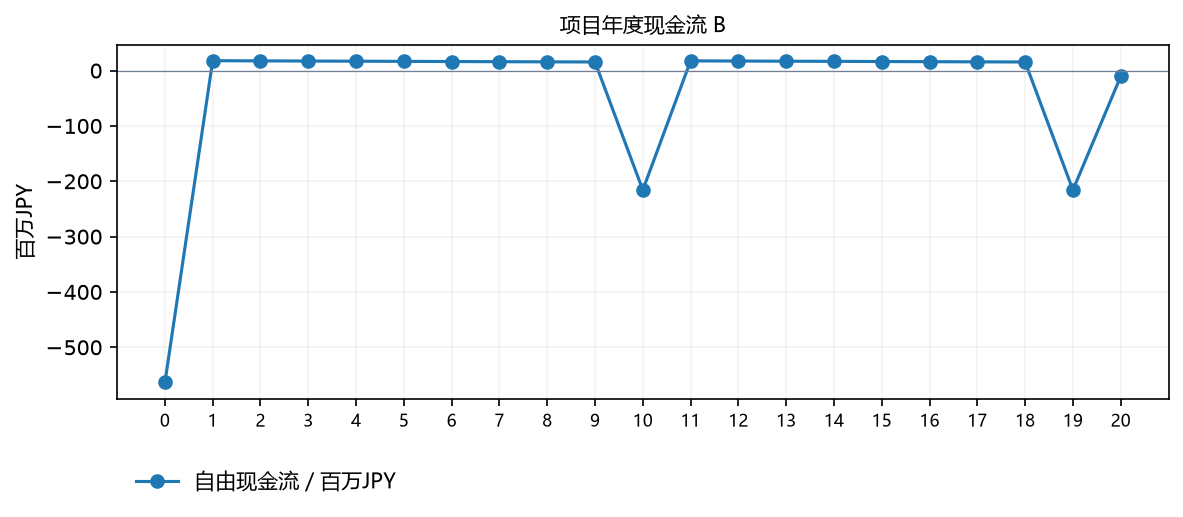

In [4]:
base=next(d for d in E['defaults'] if d['region']=='chubu' and d['scenario']=='base' and d['costID']=='base')
graph('项目年度现金流 B',[('自由现金流 / 百万JPY',[r['freeCashflow']/1e6 for r in base['rows']])],[str(r['year']) for r in base['rows']],'百万JPY','economics-cashflow.png')
heat=E['sensitivity']['base-chubu']['heatmap'];np.testing.assert_allclose(heat[2][4]['npv'],base['npv'])
R=read('research/feasibility/report-data.json');contract=next(f for f in R['figures'] if f['id']=='cashflow')
np.testing.assert_allclose(contract['series'][0]['values'],[r['freeCashflow']/1e6 for r in base['rows'][1:]])
for p,v in baseline['protected_files'].items():assert sha(ROOT/p)==v
print('REPLAY_PASSED: public cost raw -> A references / C budget -> saved executed market paths -> lifetime cash -> DCF -> chart contract. Negative NPV and IRR status preserved.')
